# Pokémon Model with Your Selected Features

## tl;dr

- Selected model: **Logistic Regression**, using **43 requested numeric inputs**.
- Five-fold development accuracy: **65.86%**; fold-to-fold standard deviation **1.02 percentage points**.
- Separate holdout accuracy: **67.33%** (1,346 of 1,999 battles).
- **7 training records** with inputs identical to supplied test records were excluded, leaving **9,993 eligible battles**.
- The test file has no winner labels, so actual test accuracy is unavailable locally.

Inputs are read from `data/`; the final estimator is saved in
`models/selected-features/model.joblib`, and predictions in
`submission-selected-features.csv`.


## Context & Methods

There are **43 numeric inputs**: the 26 explicitly named features plus one count
for each of the 17 real elemental types. `notype` is a missing-secondary-type
placeholder and is excluded. The requested `p1-switch` spelling is normalized to
`p1_switch`. No species identities, outcome-derived rates or extra features enter
the models.

| Features | Definition |
| --- | --- |
| `p1_mean_{hp,atk,def,spa,spd,spe}` | Mean base stat over P1's roster |
| `p1_type_{type}_count` | Number of P1 roster members carrying each real type |
| `p1_team_diversity` | Number of distinct real types in P1's roster |
| `p2_lead_{hp,atk,def,spa,spd,spe}` | Supplied P2 lead's base stats |
| `p1_alive_at_turn30`, `p2_alive_at_turn30` | Six minus distinct Pokémon observed fainted |
| `alive_diff_at_turn30` | P1 remaining count minus P2 remaining count |
| `p1_mean_boosts`, `p2_mean_boosts` | Mean across turns of the sum of the five boost stages |
| `p1_no_of_moves`, `p2_no_of_moves` | Number of non-null recorded moves |
| `p1_dmg`, `p2_dmg` | Positive observed opponent HP drops, summed by Pokémon |
| `p1_heal`, `p2_heal` | Positive observed own HP increases, summed by Pokémon |
| `p1_switch`, `p2_switch` | Consecutive active-name changes, including forced replacements |

### Key assumptions

All timeline features stop after the first 30 entries. Fainted means zero HP or
status `fnt`, with each name counted once. Sleep and freeze do not imply fainting;
unseen members are presumed remaining in a six-member team.

Damage/healing compare the same Pokémon's successive observations, including
returns after switching. A newly seen Pokémon starts from an assumed HP of 1.0,
matching the earlier project's depletion proxy. These totals include changes
from unobserved intervals and do not prove which move caused them. HP units are
fractions of a Pokémon's maximum, not absolute HP points.

After excluding training records with inputs identical to test records, a fixed
seed reserves approximately 20% of the remaining labelled training battles as a holdout.
Both candidates use the same **five group-stratified folds** within the other 80%.
Duplicate input content stays together. The candidate with the highest mean
cross-validation accuracy is selected, then checked once on the holdout.
Scaling is fitted separately inside each Logistic Regression training fold.


## Data

Run from this project folder or a subfolder. Required inputs are `train.jsonl`,
`test.jsonl`, and `sample_submission.csv` inside `data/`. The sample submission
supplies IDs and row order; its labels are never treated as true outcomes.


In [1]:
import copy
import hashlib
import json
import platform
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
N_FOLDS = 5
TEAM_SIZE = 6
MAX_OBSERVED_TURNS = 30


def find_project_root():
    current = Path.cwd().resolve()
    required = ('train.jsonl', 'test.jsonl', 'sample_submission.csv')
    for candidate in (current, *current.parents):
        if all((candidate / 'data' / name).is_file() for name in required):
            return candidate
    raise FileNotFoundError('Start this notebook in the project folder containing data/ or a subfolder.')


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'models' / 'selected-features'
SUBMISSION_PATH = PROJECT_ROOT / 'submission-selected-features.csv'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def load_battles(path):
    with path.open(encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]


train_data = load_battles(DATA_DIR / 'train.jsonl')
test_data = load_battles(DATA_DIR / 'test.jsonl')
if not train_data or not test_data:
    raise ValueError('Training and test files must both contain battles.')
if not all(battle.get('player_won') in (0, 1) for battle in train_data):
    raise ValueError('Every training record needs a binary player_won label.')
print(f'Data folder: {DATA_DIR}')
print(f'Training battles: {len(train_data):,}; test battles: {len(test_data):,}')
print(f'Test records with winner labels: {sum("player_won" in battle for battle in test_data):,}')


Matplotlib is building the font cache; this may take a moment.


Data folder: /Users/amrhsnd/Desktop/FDS/2026/Challange/data
Training battles: 10,000; test battles: 5,000
Test records with winner labels: 0


### Extract exactly the selected inputs

The feature list is fixed before fitting and shared by train/test. All type-count
columns exist even when their count is zero. IDs and winner labels stay outside
the feature matrix.


In [2]:
STATS = ('hp', 'atk', 'def', 'spa', 'spd', 'spe')
TYPES = (
    'bug', 'dark', 'dragon', 'electric', 'fighting', 'fire', 'flying',
    'ghost', 'grass', 'ground', 'ice', 'normal', 'poison', 'psychic',
    'rock', 'steel', 'water',
)
BOOST_STATS = ('atk', 'def', 'spa', 'spd', 'spe')
FEATURE_COLUMNS = (
    [f'p1_mean_{stat}' for stat in STATS]
    + [f'p1_type_{kind}_count' for kind in TYPES]
    + ['p1_team_diversity']
    + [f'p2_lead_{stat}' for stat in STATS]
    + ['p1_alive_at_turn30', 'p2_alive_at_turn30', 'alive_diff_at_turn30']
    + ['p1_mean_boosts', 'p2_mean_boosts']
    + ['p1_no_of_moves', 'p2_no_of_moves']
    + ['p1_dmg', 'p1_heal', 'p2_dmg', 'p2_heal', 'p1_switch', 'p2_switch']
)
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS)) == 43


def extract_selected_features(battle):
    roster = battle.get('p1_team_details') or []
    lead = battle.get('p2_lead_details') or {}
    timeline = (battle.get('battle_timeline') or [])[:MAX_OBSERVED_TURNS]
    features = {}
    for stat in STATS:
        features[f'p1_mean_{stat}'] = float(np.mean([
            pokemon.get(f'base_{stat}', 0) for pokemon in roster
        ])) if roster else 0.0
    type_counts = Counter(
        str(kind).lower()
        for pokemon in roster
        for kind in pokemon.get('types', [])
        if str(kind).lower() != 'notype'
    )
    unknown_types = set(type_counts) - set(TYPES)
    if unknown_types:
        raise ValueError(f'Unknown real roster types: {sorted(unknown_types)}')
    for kind in TYPES:
        features[f'p1_type_{kind}_count'] = type_counts[kind]
    features['p1_team_diversity'] = len(type_counts)
    for stat in STATS:
        features[f'p2_lead_{stat}'] = lead.get(f'base_{stat}', 0)

    fainted = {'p1': set(), 'p2': set()}
    previous_hp = {'p1': {}, 'p2': {}}
    previous_name = {'p1': None, 'p2': None}
    boost_sums = {'p1': [], 'p2': []}
    for side in ('p1', 'p2'):
        features[f'{side}_no_of_moves'] = 0
        features[f'{side}_dmg'] = 0.0
        features[f'{side}_heal'] = 0.0
        features[f'{side}_switch'] = 0

    for turn in timeline:
        for side in ('p1', 'p2'):
            opponent = 'p2' if side == 'p1' else 'p1'
            state = turn.get(f'{side}_pokemon_state') or {}
            name = state.get('name')
            boosts = state.get('boosts') or {}
            boost_sums[side].append(sum(boosts.get(stat, 0) for stat in BOOST_STATS))
            features[f'{side}_no_of_moves'] += turn.get(f'{side}_move_details') is not None
            if not name:
                previous_name[side] = None
                continue
            if previous_name[side] is not None and previous_name[side] != name:
                features[f'{side}_switch'] += 1
            previous_name[side] = name
            hp = state.get('hp_pct')
            if hp == 0 or state.get('status') == 'fnt':
                fainted[side].add(name)
            if hp is not None:
                hp = float(hp)
                old_hp = previous_hp[side].get(name, 1.0)
                features[f'{opponent}_dmg'] += max(old_hp - hp, 0.0)
                features[f'{side}_heal'] += max(hp - old_hp, 0.0)
                previous_hp[side][name] = hp

    for side in ('p1', 'p2'):
        features[f'{side}_alive_at_turn30'] = TEAM_SIZE - len(fainted[side])
        features[f'{side}_mean_boosts'] = float(np.mean(boost_sums[side])) if boost_sums[side] else 0.0
    features['alive_diff_at_turn30'] = features['p1_alive_at_turn30'] - features['p2_alive_at_turn30']
    assert set(features) == set(FEATURE_COLUMNS)
    return features


def make_feature_frame(battles):
    frame = pd.DataFrame([extract_selected_features(battle) for battle in battles], columns=FEATURE_COLUMNS)
    if not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError('All selected features must be finite numeric values.')
    return frame


X = make_feature_frame(train_data)
X_test = make_feature_frame(test_data)
y = np.array([battle['player_won'] for battle in train_data], dtype=int)
print(f'Features: {X.shape[1]}; train shape: {X.shape}; test shape: {X_test.shape}')
display(pd.DataFrame({'feature': FEATURE_COLUMNS}))


Features: 43; train shape: (10000, 43); test shape: (5000, 43)


,feature
0,p1_mean_hp
1,p1_mean_atk
2,p1_mean_def
3,p1_mean_spa
4,p1_mean_spd
5,p1_mean_spe
6,p1_type_bug_count
7,p1_type_dark_count
8,p1_type_dragon_count
9,p1_type_electric_count


### Train/test overlap audit

Compare inputs without `battle_id` or `player_won`. The normalized check also
removes `notype` padding and sorts roster/lead type lists. The feature-vector
check is reported separately: identical aggregate features do not prove identical
battle content. Shared IDs alone do not establish leakage when numbering restarts.

Any training record whose normalized inputs match a test record is excluded from
both model selection and final fitting. The source files remain unchanged. This
audit detects duplicate inputs; it cannot establish how or when duplication arose.


In [3]:
def battle_input_group(battle):
    # Normalize only non-informative type padding/order, then exclude ID/target.
    payload = {
        key: value for key, value in battle.items()
        if key not in ('battle_id', 'player_won')
    }
    payload['p1_team_details'] = [
        {**pokemon, 'types': sorted(str(kind).lower() for kind in pokemon.get('types', []) if str(kind).lower() != 'notype')}
        for pokemon in battle.get('p1_team_details', [])
    ]
    lead = battle.get('p2_lead_details') or {}
    payload['p2_lead_details'] = {
        **lead, 'types': sorted(str(kind).lower() for kind in lead.get('types', []) if str(kind).lower() != 'notype')
    }
    canonical = json.dumps(payload, sort_keys=True, separators=(',', ':'), allow_nan=False)
    return hashlib.sha256(canonical.encode('utf-8')).hexdigest()



def raw_input_group(battle):
    payload = {key: value for key, value in battle.items() if key not in ('battle_id', 'player_won')}
    canonical = json.dumps(payload, sort_keys=True, separators=(',', ':'), allow_nan=False)
    return hashlib.sha256(canonical.encode('utf-8')).hexdigest()


def overlap_counts(train_keys, test_keys):
    train_counts, test_counts = Counter(train_keys), Counter(test_keys)
    shared = set(train_counts) & set(test_counts)
    return {
        'unique_shared_groups': len(shared),
        'train_rows_in_shared_groups': sum(train_counts[key] for key in shared),
        'test_rows_in_shared_groups': sum(test_counts[key] for key in shared),
        'matching_train_test_pairs': sum(train_counts[key] * test_counts[key] for key in shared),
    }


raw_train_groups = [raw_input_group(battle) for battle in train_data]
raw_test_groups = [raw_input_group(battle) for battle in test_data]
all_train_groups = np.array([battle_input_group(battle) for battle in train_data])
test_groups = np.array([battle_input_group(battle) for battle in test_data])
train_feature_keys = [tuple(row) for row in X.to_numpy()]
test_feature_keys = [tuple(row) for row in X_test.to_numpy()]
raw_overlap = overlap_counts(raw_train_groups, raw_test_groups)
normalized_overlap = overlap_counts(all_train_groups, test_groups)
feature_overlap = overlap_counts(train_feature_keys, test_feature_keys)
shared_content = set(all_train_groups) & set(test_groups)
shared_ids = set(battle['battle_id'] for battle in train_data) & set(battle['battle_id'] for battle in test_data)

train_indices_by_group = {}
for index, group in enumerate(all_train_groups):
    train_indices_by_group.setdefault(group, []).append(index)
match_rows = []
for test_index, group in enumerate(test_groups):
    for train_index in train_indices_by_group.get(group, []):
        match_rows.append({
            'train_battle_id': train_data[train_index]['battle_id'],
            'test_battle_id': test_data[test_index]['battle_id'],
            'exact_raw_input_match': raw_train_groups[train_index] == raw_test_groups[test_index],
            'normalized_input_sha256': str(group),
        })
match_table = pd.DataFrame(match_rows, columns=[
    'train_battle_id', 'test_battle_id', 'exact_raw_input_match', 'normalized_input_sha256',
])
match_table.to_csv(OUTPUT_DIR / 'train_test_overlap.csv', index=False)

leakage_audit = {
    'source_train_rows': len(train_data), 'source_test_rows': len(test_data),
    'shared_ids': len(shared_ids),
    'exact_inputs_excluding_id_and_label': raw_overlap,
    'normalized_inputs_excluding_id_and_label': normalized_overlap,
    'identical_requested_feature_vectors': feature_overlap,
    'train_duplicate_rows_beyond_first': len(train_data) - len(set(all_train_groups)),
    'test_duplicate_rows_beyond_first': len(test_data) - len(set(test_groups)),
    'policy': 'Exclude every training row whose normalized inputs match any supplied test row; do not edit source files.',
    'interpretation': 'Cross-file duplicate inputs are present if shared groups > 0; the direction/cause of duplication is unknown.',
}
comparison_rows = []
for label, result in [
    ('Exact input content (excluding ID/label)', raw_overlap),
    ('Normalized input content', normalized_overlap),
    ('Same feature vector (not proof of input duplication)', feature_overlap),
]:
    comparison_rows.append({'check': label, **result})
display(pd.DataFrame(comparison_rows))
print(f'Shared IDs: {len(shared_ids):,}; IDs alone are not used as evidence of leakage.')
if len(match_table):
    display(match_table[['train_battle_id', 'test_battle_id', 'exact_raw_input_match']])

eligible = np.array([group not in shared_content for group in all_train_groups], dtype=bool)
model_train_data = [battle for battle, keep in zip(train_data, eligible) if keep]
X = X.loc[eligible].reset_index(drop=True)
y = y[eligible]
groups = all_train_groups[eligible]
assert not set(groups) & set(test_groups)
leakage_audit['excluded_training_rows'] = int(np.sum(~eligible))
leakage_audit['eligible_training_rows'] = len(X)
leakage_audit['model_training_test_content_overlap'] = 0
(OUTPUT_DIR / 'leakage_audit.json').write_text(json.dumps(leakage_audit, indent=2), encoding='utf-8')
print(f'Excluded matching training rows: {np.sum(~eligible):,}')
print(f'Eligible training battles: {len(X):,}; remaining train/test content overlap: 0')


,check,unique_shared_groups,train_rows_in_shared_groups,test_rows_in_shared_groups,matching_train_test_pairs
0,Exact input content (excluding ID/label),7,7,7,7
1,Normalized input content,7,7,7,7
2,Same feature vector (not proof of input duplic...,8,8,8,8


Shared IDs: 5,000; IDs alone are not used as evidence of leakage.


,train_battle_id,test_battle_id,exact_raw_input_match
0,5648,900,True
1,1664,1000,True
2,6940,1955,True
3,8085,2579,True
4,2947,3855,True
5,4041,4087,True
6,4209,4182,True


Excluded matching training rows: 7
Eligible training battles: 9,993; remaining train/test content overlap: 0


## Results

### Five-fold cross-validation and model selection

The separate holdout remains outside these five folds. The two candidates have
fixed settings; the holdout is not used for tuning or choosing between them.


In [4]:
outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
development_indices, holdout_indices = next(outer_splitter.split(X, y, groups))
X_development = X.iloc[development_indices]
y_development = y[development_indices]
development_groups = groups[development_indices]
assert not set(development_groups) & set(groups[holdout_indices])

cv_splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + 1)
cv_splits = list(cv_splitter.split(X_development, y_development, development_groups))
for fit_rows, validation_rows in cv_splits:
    assert not set(development_groups[fit_rows]) & set(development_groups[validation_rows])
    assert len(np.unique(y_development[fit_rows])) == len(np.unique(y_development[validation_rows])) == 2

candidates = {
    'Logistic Regression': make_pipeline(
        StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)
    ),
    'Histogram Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.06, max_leaf_nodes=15,
        min_samples_leaf=25, l2_regularization=5.0,
        early_stopping=False, random_state=SEED,
    ),
}
cv_rows = []
fold_rows = []
for name, candidate in candidates.items():
    print(f'Running {N_FOLDS}-fold CV: {name}...', flush=True)
    with threadpool_limits(limits=4):
        scores = cross_validate(
            candidate, X_development, y_development, cv=cv_splits, n_jobs=1,
            scoring={'accuracy': 'accuracy', 'roc_auc': 'roc_auc', 'neg_log_loss': 'neg_log_loss'},
            error_score='raise',
        )
    cv_rows.append({
        'model': name,
        'mean_accuracy': float(np.mean(scores['test_accuracy'])),
        'std_accuracy': float(np.std(scores['test_accuracy'])),
        'mean_roc_auc': float(np.mean(scores['test_roc_auc'])),
        'mean_log_loss': float(-np.mean(scores['test_neg_log_loss'])),
    })
    for fold, (fit_rows, validation_rows) in enumerate(cv_splits, 1):
        fold_rows.append({
            'model': name, 'fold': fold, 'fit_rows': len(fit_rows), 'validation_rows': len(validation_rows),
            'accuracy': float(scores['test_accuracy'][fold-1]),
        })

cv_results = pd.DataFrame(cv_rows).sort_values(
    ['mean_accuracy', 'mean_log_loss', 'model'], ascending=[False, True, True]
).reset_index(drop=True)
fold_results = pd.DataFrame(fold_rows)
best_name = cv_results.iloc[0]['model']
print(f'Development battles: {len(development_indices):,}; held-out battles: {len(holdout_indices):,}')
display(cv_results.style.format({
    'mean_accuracy': '{:.2%}', 'std_accuracy': '{:.2%}',
    'mean_roc_auc': '{:.4f}', 'mean_log_loss': '{:.4f}',
}))
display(fold_results.style.format({'accuracy': '{:.2%}'}))
print(f'Selected by mean five-fold accuracy: {best_name}')


Running 5-fold CV: Logistic Regression...


Running 5-fold CV: Histogram Gradient Boosting...


Development battles: 7,994; held-out battles: 1,999


,model,mean_accuracy,std_accuracy,mean_roc_auc,mean_log_loss
0,Logistic Regression,65.86%,1.02%,0.7184,0.6142
1,Histogram Gradient Boosting,65.32%,0.85%,0.7127,0.6195


,model,fold,fit_rows,validation_rows,accuracy
0,Logistic Regression,1,6395,1599,67.10%
1,Logistic Regression,2,6395,1599,66.60%
2,Logistic Regression,3,6395,1599,64.23%
3,Logistic Regression,4,6396,1598,65.27%
4,Logistic Regression,5,6395,1599,66.10%
5,Histogram Gradient Boosting,1,6395,1599,64.17%
6,Histogram Gradient Boosting,2,6395,1599,66.23%
7,Histogram Gradient Boosting,3,6395,1599,64.67%
8,Histogram Gradient Boosting,4,6396,1598,66.33%
9,Histogram Gradient Boosting,5,6395,1599,65.23%


Selected by mean five-fold accuracy: Logistic Regression


### Independent holdout accuracy

A fresh clone of the selected candidate is fitted on all development rows, then
scored on the holdout. This is validation accuracy, not a score on unlabelled
`test.jsonl`.


Selected model: Logistic Regression
Five-fold development accuracy: 65.86%
Holdout accuracy: 67.33% (1,346 / 1,999)
Holdout ROC-AUC: 0.7403
Holdout majority-class reference: 50.03%


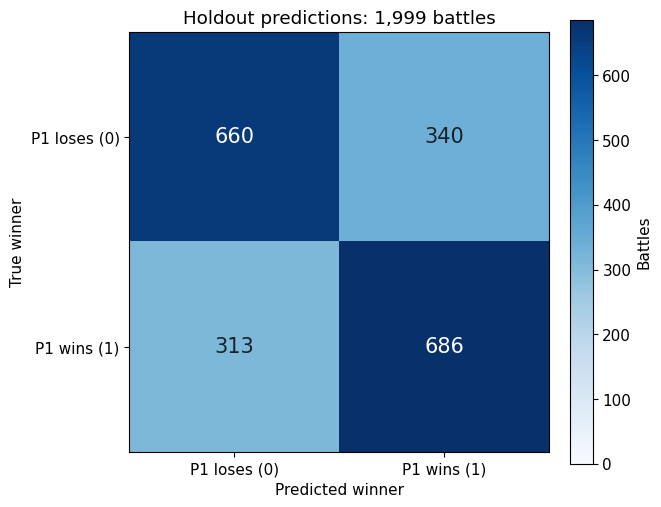

In [5]:
validation_model = clone(candidates[best_name])
with threadpool_limits(limits=4):
    validation_model.fit(X_development, y_development)
    holdout_probabilities = validation_model.predict_proba(X.iloc[holdout_indices])[:, 1]
holdout_predictions = validation_model.classes_[np.argmax(
    np.column_stack([1.0-holdout_probabilities, holdout_probabilities]), axis=1
)]
holdout_y = y[holdout_indices]
holdout_accuracy = float(accuracy_score(holdout_y, holdout_predictions))
correct = int(np.sum(holdout_y == holdout_predictions))
holdout_metrics = {
    'accuracy': holdout_accuracy,
    'correct': correct,
    'rows': len(holdout_indices),
    'roc_auc': float(roc_auc_score(holdout_y, holdout_probabilities)),
    'log_loss': float(log_loss(holdout_y, holdout_probabilities, labels=[0, 1])),
    'confusion_matrix': confusion_matrix(holdout_y, holdout_predictions, labels=[0, 1]).tolist(),
    'majority_accuracy': float(np.max(np.bincount(holdout_y, minlength=2)) / len(holdout_y)),
}
print(f'Selected model: {best_name}')
print(f'Five-fold development accuracy: {cv_results.iloc[0]["mean_accuracy"]:.2%}')
print(f'Holdout accuracy: {holdout_accuracy:.2%} ({correct:,} / {len(holdout_indices):,})')
print(f'Holdout ROC-AUC: {holdout_metrics["roc_auc"]:.4f}')
print(f'Holdout majority-class reference: {holdout_metrics["majority_accuracy"]:.2%}')

plt.rcParams.update({'font.size': 11, 'font.family': 'DejaVu Sans'})
matrix = np.array(holdout_metrics['confusion_matrix'])
fig, ax = plt.subplots(figsize=(6.5, 5.2), constrained_layout=True)
image = ax.imshow(matrix, cmap='Blues', vmin=0)
for row in range(2):
    for column in range(2):
        ax.text(column, row, f'{matrix[row, column]:,}', ha='center', va='center',
                color='white' if matrix[row,column] > matrix.max()/2 else '#17212b', fontsize=15)
ax.set(xticks=[0,1], yticks=[0,1], xticklabels=['P1 loses (0)', 'P1 wins (1)'],
       yticklabels=['P1 loses (0)', 'P1 wins (1)'], xlabel='Predicted winner', ylabel='True winner',
       title=f'Holdout predictions: {len(holdout_indices):,} battles')
fig.colorbar(image, ax=ax, label='Battles')
plt.show()


### Train the final model and export predictions

The selected configuration is now refitted on all eligible labelled training battles after excluding test-content matches.
The saved estimator contains only the chosen classifier and its required scaling.
The model bundle records the 43-column order and assumptions. Test prediction
rows are matched to the sample template by `battle_id`.


In [6]:
final_model = clone(candidates[best_name])
with threadpool_limits(limits=4):
    final_model.fit(X, y)
    test_predictions = final_model.predict(X_test)

sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
if list(sample_submission.columns) != ['battle_id', 'player_won']:
    raise ValueError('Unexpected sample submission columns.')
test_ids = pd.Series([battle['battle_id'] for battle in test_data])
if not test_ids.is_unique or not sample_submission['battle_id'].is_unique:
    raise ValueError('Submission and test IDs must be unique.')
if set(test_ids) != set(sample_submission['battle_id']):
    raise ValueError('Submission and test IDs must match exactly.')
predictions_by_id = pd.Series(test_predictions, index=test_ids)
submission = sample_submission.copy()
submission['player_won'] = submission['battle_id'].map(predictions_by_id)
if submission['player_won'].isna().any():
    raise ValueError('Some template rows have no matching prediction.')
submission['player_won'] = submission['player_won'].astype(int)
submission.to_csv(SUBMISSION_PATH, index=False)

assumptions = {
    'timeline_entries': MAX_OBSERVED_TURNS,
    'team_size': TEAM_SIZE,
    'type_padding_excluded': 'notype',
    'switch_name_normalized': 'p1-switch -> p1_switch',
    'damage': 'Sum observed opponent HP drops by species; first previous HP defaults to 1.0.',
    'healing': 'Sum observed own HP increases by species.',
    'switches': 'Adjacent active-name changes, including forced replacements.',
    'mean_boosts': 'Mean across observed turns of summed atk/def/spa/spd/spe boost stages.',
}
joblib.dump({
    'model': final_model, 'feature_columns': FEATURE_COLUMNS,
    'model_name': best_name, 'assumptions': assumptions,
}, OUTPUT_DIR / 'model.joblib')

source_hashes = {}
for filename in ('train.jsonl', 'test.jsonl', 'sample_submission.csv'):
    digest = hashlib.sha256()
    with (DATA_DIR / filename).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024*1024), b''):
            digest.update(chunk)
    source_hashes[filename] = digest.hexdigest()
results = {
    'feature_count': len(FEATURE_COLUMNS), 'feature_columns': FEATURE_COLUMNS,
    'source_training_rows': len(train_data), 'eligible_training_rows': len(X),
    'leakage_audit': leakage_audit,
    'selected_model': best_name, 'seed': SEED, 'development_folds': N_FOLDS,
    'development_rows': len(development_indices), 'holdout_rows': len(holdout_indices),
    'unique_input_groups': int(len(np.unique(groups))),
    'group_overlap_holdout': 0, 'group_overlap_cv_folds': 0,
    'selection_rule': 'Highest mean five-fold development accuracy; log loss is the tie-breaker.',
    'cv_results': cv_results.to_dict(orient='records'),
    'fold_results': fold_results.to_dict(orient='records'),
    'holdout': holdout_metrics, 'assumptions': assumptions,
    'source_sha256': source_hashes,
    'versions': {'python': platform.python_version(), 'scikit_learn': sklearn.__version__,
                 'numpy': np.__version__, 'pandas': pd.__version__},
    'test_accuracy': None,
    'test_accuracy_note': 'No true winner labels are available in the supplied test.jsonl.',
}
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
cv_results.to_csv(OUTPUT_DIR / 'cross_validation.csv', index=False)
fold_results.to_csv(OUTPUT_DIR / 'fold_results.csv', index=False)
pd.DataFrame({
    'battle_id': [model_train_data[index]['battle_id'] for index in holdout_indices],
    'player_won': holdout_y, 'prediction': holdout_predictions,
    'p1_win_probability': holdout_probabilities,
}).to_csv(OUTPUT_DIR / 'holdout_predictions.csv', index=False)

loaded_bundle = joblib.load(OUTPUT_DIR / 'model.joblib')
with threadpool_limits(limits=4):
    reloaded_predictions = loaded_bundle['model'].predict(X_test.iloc[:20])
assert np.array_equal(reloaded_predictions, test_predictions[:20])
print(f'Saved model: {OUTPUT_DIR / "model.joblib"}')
print(f'Saved metrics: {OUTPUT_DIR / "metrics.json"}')
print(f'Saved {len(submission):,} test predictions: {SUBMISSION_PATH}')
print('Saved-model reload check passed.')
display(submission.head())


Saved model: /Users/amrhsnd/Desktop/FDS/2026/Challange/models/selected-features/model.joblib
Saved metrics: /Users/amrhsnd/Desktop/FDS/2026/Challange/models/selected-features/metrics.json
Saved 5,000 test predictions: /Users/amrhsnd/Desktop/FDS/2026/Challange/submission-selected-features.csv
Saved-model reload check passed.


,battle_id,player_won
0,0,1
1,1,1
2,2,0
3,3,0
4,4,1


## Takeaways

The selected Logistic Regression model achieved 65.86%
mean accuracy across five development folds and 67.33%
on the separate 1,999-battle holdout. The holdout was excluded
from candidate selection. These results describe held-out training battles; the
true score on `test.jsonl` remains unknown.

The overlap audit found 7 cross-file duplicate input groups.
Their matching training rows are excluded from all fitting; original files are
unchanged. The final saved model is refitted on all 9,993 eligible battles.
